# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 8. Вероятность


**Правила, <font color="red">прочитайте внимательно</font>:**

1. Общее

     * Выполненную работу **в формате `ipynb`** нужно отправить по ссылке "Сдача ДЗ" на <a href="https://thetahat.ru/courses/ad"><b>странице курса</b></a>. **Работы, присланные иным способом, не принимаются.** Дедлайны указаны в боте и на сайте, они являются строгими.
     
     * Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><b>руководство по оформлению ДЗ</b></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.
     
     * Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><b>правила использования ИИ-инструментов</b></a> при решении домашнего задания.
     
     * Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф -3 скор-балла к итоговой оценке.**
     
     * Решение теоретических задач оформляйте в markdown-ячейках формате $\LaTeX$. При решении можно использовать ИИ-инструменты только для оформления написанного самостоятельно решения. Например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.
     
     * Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
     </br>

2. Правила заполнения ноутбука

     * Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.
     * Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены `<...>`.
     * Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках.
     * Условия <font color="red"><b>запрещается модифицировать</b></font>.
     * При нарушении данных правил работа может получить 0 баллов.
</br>


**Баллы за задание**

* Задача 1 &mdash; 60 баллов
* Задача 2 &mdash; 40 баллов
* Задача 3 &mdash; 100 баллов

In [ ]:
# Bot check

# HW_ID: fpmi_ad8
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from functools import partial
from scipy.stats import norm, cauchy

sns.set(style="whitegrid", palette="Set2")

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1, 2, 3**
1. https://chat.deepseek.com/share/pq4smghzdgkmygndcb
    - спрашивала про методы с семинара и про синтаксис


#### Поправки

**Задача 1:**
- Исправлен генератор начального значения внутри функции исследования n_bits (одни и те же броски для всех значений)
- Гистограммы n_bits вынесены на отдельные подграфики рядом друг с другом

**Задача 2:**
- Добавлен общий график для нескольких выборок (пункт 2)
- Добавлены графики для нескольких выборок медианы (пункт 3)
- Добавлен общий график для большого числа выборок

**Задача 3:**
- Серый фон для всех графиков
- На логарифмическом графике явно подписано, что ось $X$ логарифмирована
- При $p=0.5$ цепь Маркова должна давать то же $n$, что и пункт 1 — исправлена инициализация и добавлено сравнение

---
### Задача 1.

**При решении данной задачи можно использовать ИИ-инструменты только для построения графиков и оформления документации к коду. Использование ИИ-инструментов для решения контеста запрещено.**

Современные библиотеки для генерации используют алгоритмы вроде PCG64 (Permuted Congruential Generator-64), который достаточно быстро генерирует случайные 64-битные целые числа. Если их отнормировать на максимально возможное число ($2^{64}-1$), мы получим равномерное распределение $U(0, 1)$.

В рамках этой задачи для лучшего понимания взаимосвязей случайных величин мы пойдем другим путем. Будем предполагать, что у нас имеется только симметричная монета, один бросок которой моделирует случайную величину из бернуллиевского распределения с параметром $p = 0.5$.

In [46]:
# Создаем генератор случайных чисел
rng = np.random.default_rng(42)
# Фиксируем первые два аргумента функции rng.integers (low=0 и high=2)
coin = partial(rng.integers, 0, 2)

Вам предстоит написать собственные генераторы выборок из равномерного, нормального и экспоненциального распределений с заданными параметрами, используя в качестве основы исключительно броски правильной монеты. Совершать броски можно неограниченное количество раз. Тем не менее, поскольку лишние броски увеличивают время генерации, стоит использовать оптимальное количество бросков. За лишнее количество бросков могут быть сняты баллы.

**1.** Напишите функцию **`uniform`** генерации случайных величин из равномерного распределения на отрезке $[0, 1]$ с заданной точностью. Это можно сделать, записав случайную величину $\xi \sim U(0, 1)$ в двоичной системе системе счисления $\xi = 0,\xi_1\xi_2\xi_3...$. Тогда $\xi_i \sim Bern(1/2)$ и независимы в совокупности. Приближение заключается в том, что вместо генерации бесконечного количества $\xi_i$ мы полагаем $\xi = 0,\xi_1\xi_2\xi_3...\xi_n$.

Нужно реализовать функцию `uniform` так, чтобы она могла принимать на вход в качестве параметра `size` как число, так и объект `tuple` любой размерности, и возвращать объект `numpy.array` соответствующей размерности. Например, если `size=(10, 1, 5)`, то функция должна вернуть объект размера $10 \times 1 \times 5$. Аргумент `n_bits` отвечает за число $n$.

Также обратите внимание, что  функцию `coin` можно вызвать только один раз. Для совершения 10 бросков монеты используйте `coin(10)`, это считается одним вызовом функции. При реализации функций генерации нельзя использовать какие-либо циклы, а также функции `np.vectorize`, `np.apply_along_axis`, `np.fromiter` и подобные, это медленно и по сути является циклом. Используйте векторные функции `numpy`. При нарушении этих правил будут сниматься баллы.

In [47]:
def uniform(size: int | tuple = 1, n_bits: int = 50) -> float | np.ndarray:
    """
    Генерирует выборку из непрерывного равномерного распределения U(0, 1).

    Параметры
    ---------
    size: Размерность выходного массива (одно число для вектора или кортеж для тензора).
    n_bits: Количество бросков честной монеты (битов) для аппроксимации одного вещественного числа.

    Возвращает
    ----------
    Сгенерированные значения из равномерного распределения на интервале [0, 1].
    """

    # генерируем много 0 и 1, как результаты бросков честной монеты
    shape = (size,) if isinstance(size, int) else size
    bits = coin((*shape, n_bits))  # если size=(10, 1, 5), то массив формы (10, 1, 5, n_bits)
    # создаём веса для двоичной дроби
    weights = 2.0 ** -(np.arange(1, n_bits + 1))
    return np.sum(bits * weights, axis=-1)  # биты каждого объекта хранятся на последей оси

Cгенерируйте $200$ независимых случайных величин, постройте график плотности на отрезке $[-0.25, 1.25]$, а также гистограмму по сгенерированным случайным величинам. Для построения графика необходимо брать достаточно большое количество точек сетки.

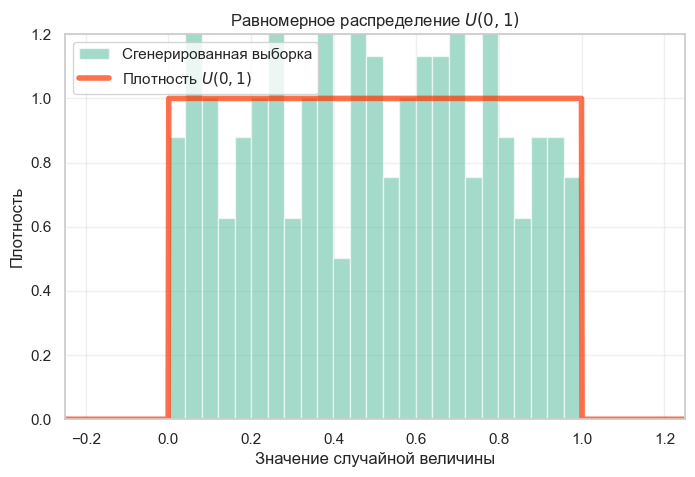

In [48]:
sample = uniform(200)

x = np.linspace(-0.25, 1.25, 1000)
y = np.where((x >= 0) & (x <= 1), 1, 0)  # плотность

plt.figure(figsize=(8, 5))
plt.hist(sample, bins=25, density=True, alpha=0.6, label="Сгенерированная выборка")
plt.plot(x, y, lw=4, alpha=0.7, label="Плотность $U(0,1)$", color="#FF3300")
plt.title("Равномерное распределение $U(0,1)$")
plt.xlabel("Значение случайной величины")
plt.ylabel("Плотность")
plt.xlim(-0.25, 1.25)
plt.ylim(0, 1.2)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Описание графика**

На графике изображена гистограмма сгенерированной выборки из равномерного распределения на отрезке $[0,1]$, а также плотность этого распределения.
Гистограмма показывает распределение значений, полученных с помощью функции `uniform`. Оранжевой линией показана плотность распределения, равная 1 на отрезке $[0,1]$ и 0 вне его.

**Вывод:**
Полученная выборка достаточно хорошо приближает равномерное распределение. Значения распределены равномерно по интервалу $[0,1]$, что подтверждает корректность реализации.

Исследуйте, как меняются значения случайных величин в зависимости от `n_bits` в написанной ранее вами функции.

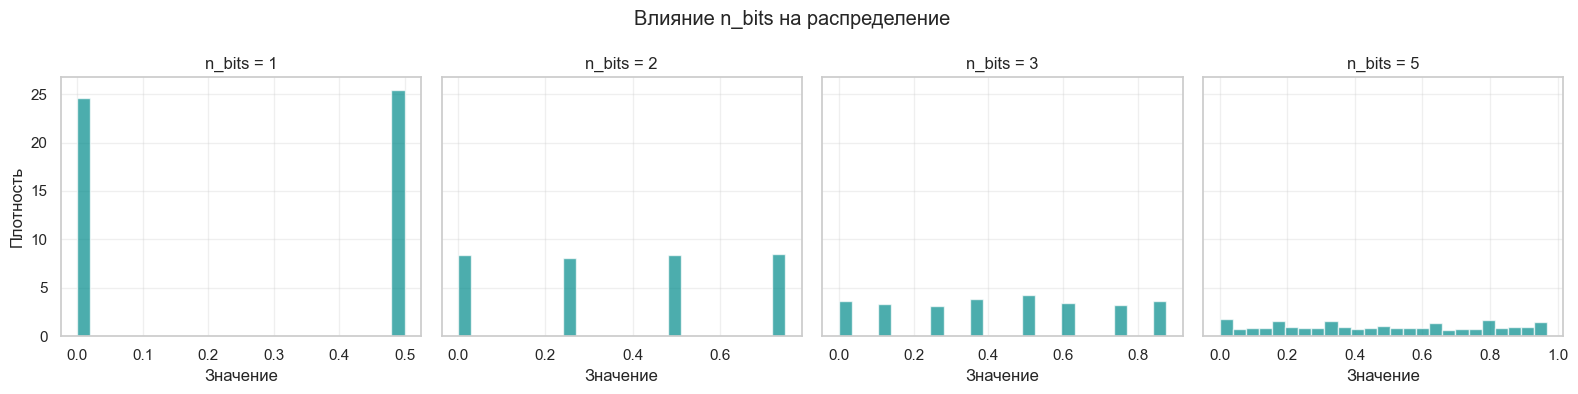

In [50]:
n_bits_list = [1, 2, 3, 5]
n_samples = 1000

fig, axes = plt.subplots(1, len(n_bits_list), figsize=(16, 4), sharey=True)

for ax, n in zip(axes, n_bits_list):
    rng = np.random.default_rng(42)
    coin = partial(rng.integers, 0, 2)
    values = uniform(n_samples, n_bits=n)
    ax.hist(values, bins=25, density=True, alpha=0.7, color="darkcyan")
    ax.set_title(f"n_bits = {n}")
    ax.set_xlabel("Значение")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Плотность")
fig.suptitle("Влияние n_bits на распределение")
plt.tight_layout()
plt.show()

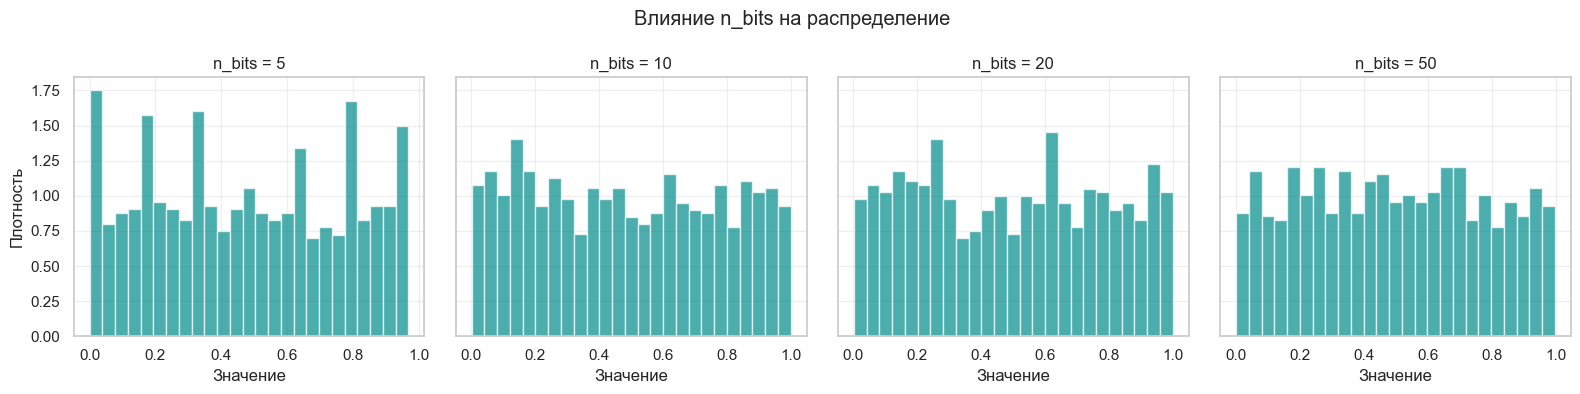

In [49]:
n_bits_list = [5, 10, 20, 50]
n_samples = 1000

fig, axes = plt.subplots(1, len(n_bits_list), figsize=(16, 4), sharey=True)

for ax, n in zip(axes, n_bits_list):
    rng = np.random.default_rng(42)
    coin = partial(rng.integers, 0, 2)
    values = uniform(n_samples, n_bits=n)
    ax.hist(values, bins=25, density=True, alpha=0.7, color="darkcyan")
    ax.set_title(f"n_bits = {n}")
    ax.set_xlabel("Значение")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Плотность")
fig.suptitle("Влияние n_bits на распределение")
plt.tight_layout()
plt.show()

**Описание графика:**

На графике показано, как изменяется распределение случайных величин при различных значениях параметра `n_bits`.
Каждая гистограмма соответствует своему значению `n_bits` и отражает распределение 1000 сгенерированных значений.

**Вывод:**

При малых значениях `n_bits` (например, до 5) распределение становится более дискретным: значения принимают только несколько возможных уровней, нет плавного перехода. 

С увеличением `n_bits` (10, 20, 50) распределение становится более гладким и всё лучше приближается к непрерывному равномерному распределению.

Таким образом, параметр `n_bits` напрямую влияет на точность: чем он больше, тем ближе распределение к $U(0,1)$.

**Ответ на вопрос:**

Значения случайной величины становятся более точными при увеличении `n_bits`.

Если `n_bits` маленький, то число собирается из небольшого количества битов, поэтому возможных значений мало — распределение получается ступенчатым.

Если `n_bits` большой, то число задаётся большим количеством двоичных разрядов, и значения могут принимать гораздо больше различных значений, поэтому распределение становится более плавным и похожим на равномерное.

**2.** Напишите функцию **`normal`** генерации случайных величин в количестве `size` штук из распределения $\mathcal{N}(loc, scale^2)$ с помощью преобразования Бокса-Мюллера. 

Реализация должна быть без циклов. В качестве параметра `size` может быть как число, так и объект `tuple` любой размерности. Можно использовать реализованную ранее функцию `uniform`.

При реализации `normal` допускается использовать количество бросков монеты чуть больше оптимального с целью упрощения кода. А именно, для генерации выборки размера $n$ можно использовать броски монет не более того количества, которое требуется для оптимальной генерации выборки размера $n+1$.

In [54]:
def normal(
    size: int | tuple = 1, loc: float = 0.0, scale: float = 1.0, n_bits: int = 50
) -> float | np.ndarray:
    """
    Генерирует выборку из нормального распределения N(loc, scale^2).

    Параметры
    ---------
    size: Размерность выходного массива (одно число для вектора или кортеж для тензора).
    loc: Математическое ожидание распределения.
    scale: Стандартное отклонение распределения (должно быть > 0).
    n_bits: Количество бросков честной монеты (битов) для базовой генерации U(0, 1).

    Возвращает
    ----------
    Сгенерированные значения из нормального распределения.
    """
    shape = (size,) if isinstance(size, int) else size  # приводим размер к кортежу
    total = int(np.prod(shape))  # считаем общее число элементов

    # Независимые случайные велечины
    u1 = uniform(total // 2 + 1, n_bits=n_bits)  # равномерные
    u2 = uniform(total // 2 + 1, n_bits=n_bits)

    # Формула Бокса–Мюллера
    z1 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)  # нормальные
    z2 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2)

    z = np.concatenate([z1, z2])[:total]  # объединяем и оставляем нужное количество значений
    z = z.reshape(shape)

    # Переходим от N(0,1) к N(loc, scale^2)
    return loc + scale * z

Cгенерируйте $200$ независимых случайных величин, постройте график плотности на отрезке $[-3, 3]$, а также гистограмму по сгенерированным случайным величинам.

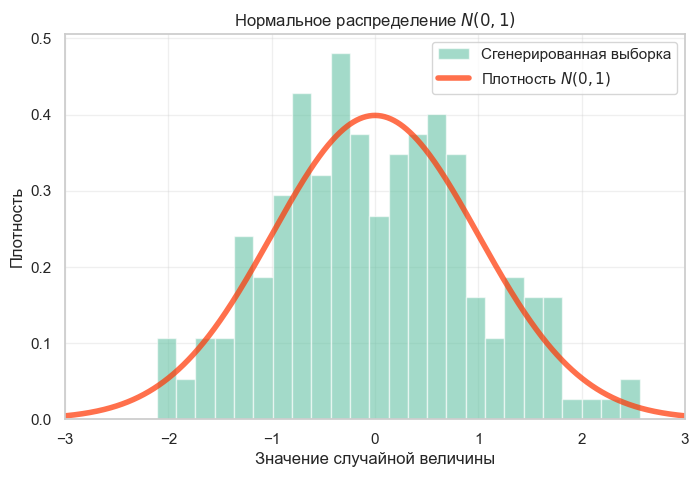

In [55]:
sample = normal(200)

x = np.linspace(-3, 3, 1000)
y = (1 / np.sqrt(2*np.pi)) * np.exp(-x**2 / 2)  # плотность

plt.figure(figsize=(8, 5))
plt.hist(sample, bins=25, density=True, alpha=0.6, label="Сгенерированная выборка")
plt.plot(x, y, lw=4, alpha=0.7, label="Плотность $N(0,1)$", color="#FF3300")
plt.title("Нормальное распределение $N(0,1)$")
plt.xlabel("Значение случайной величины")
plt.ylabel("Плотность")
plt.xlim(-3, 3)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Описание графика**

На графике изображена гистограмма сгенерированной выборки из нормального распределения $N(0,1)$, а также плотность этого распределения.  
Гистограмма показывает распределение значений, полученных с помощью функции `normal`. Оранжевой линией показана теоретическая плотность стандартного нормального распределения.

**Вывод:**

Полученная выборка хорошо приближает нормальное распределение. Видна характерная симметричная форма с максимумом около нуля и убыванием плотности по мере удаления от центра, что подтверждает корректность реализации.

**3.** Вы уже научились генерировать выборку из равномерного распределения. Напишите функцию **`expon`** генерации выборки из экспоненциального распределения, используя задачу из теории вероятностей:

*Если $\xi$ — случайная величина, имеющая абсолютно непрерывное распределение, и $F$ — ее функция распределения, то случайная величина $F(\xi)$ имеет равномерное распределение на $[0, 1]$*.

In [57]:
def expon(size: int | tuple = 1, lambd: float = 1.0, n_bits: int = 50) -> float | np.ndarray:
    """
    Генерирует выборку из экспоненциального распределения Exp(lambd).

    Параметры
    ---------
    size: Размерность выходного массива (одно число для вектора или кортеж для тензора).
    lambd: Параметр интенсивности (должно быть > 0).
    n_bits: Количество бросков честной монеты (битов) для базовой генерации U(0, 1).

    Возвращает
    ----------
    Сгенерированные значения из экспоненциального распределения.
    """
    u = uniform(size, n_bits=n_bits)
    return -np.log(1 - u) / lambd

Для $Exp(1)$ сгенерируйте выборку размера 200 и постройте график плотности этого распределения на отрезке $[-0.5, 5]$.

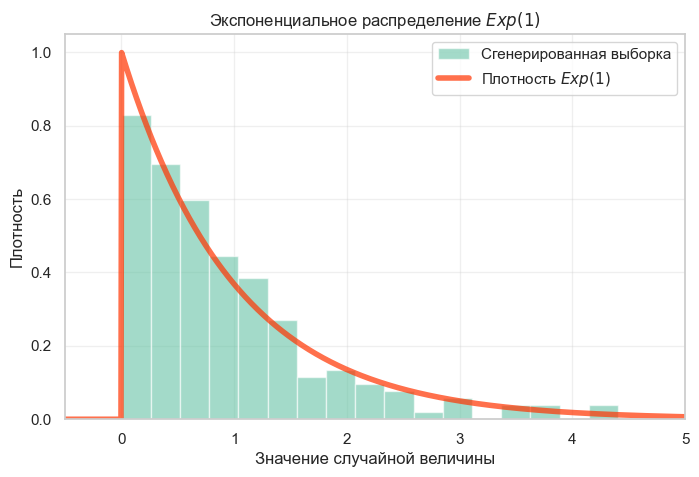

In [59]:
sample = expon(200, lambd=1.0)

x = np.linspace(-0.5, 5, 1000)
y = np.where(x >= 0, np.exp(-x), 0)

plt.figure(figsize=(8, 5))
plt.hist(sample, bins=25, density=True, alpha=0.6, label="Сгенерированная выборка")
plt.plot(x, y, lw=4, alpha=0.7, label="Плотность $Exp(1)$", color="#FF3300")
plt.title("Экспоненциальное распределение $Exp(1)$")
plt.xlabel("Значение случайной величины")
plt.ylabel("Плотность")
plt.xlim(-0.5, 5)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Описание графика**

На графике изображена гистограмма сгенерированной выборки из экспоненциального распределения $Exp(1)$, а также плотность этого распределения.  
Гистограмма показывает распределение значений, полученных с помощью функции `expon`. Оранжевой линией показана плотность распределения, равная $e^{-x}$ при $x \ge 0$ и 0 при $x < 0$.

**Вывод:**
Можно заметить, что значения сосредоточены вблизи нуля, а затем плавно убывают по мере увеличения $x$. Это соответствует характерной форме экспоненциального распределения.

**4. Выводы:**

По заданию были реализованы генераторы случайных величин для равномерного, нормального и экспоненциального распределений с использованием только бросков честной монеты.

Равномерное распределение было получено через двоичное представление числа, где каждый бит генерируется с помощью Bern(1/2). Увеличение параметра `n_bits` приводит к более точному непрерывному распределению.

Нормальное распределение было реализовано с помощью формулы Бокса–Мюллера, позволяющей получить нормально распределённые величины из равномерных. Полученные значения демонстрируют характерную симметричную колоколообразную форму.

Экспоненциальное распределение было получено с использованием метода обратной функции распределения. Сгенерированная выборка корректно отражает асимметричную форму распределения с максимумом в нуле и убывающим хвостом.

Во всех случаях гистограммы хорошо согласуются с плотностями, что подтверждает корректность реализованных методов генерации случайных величин.

---

### Задача 2.

Рассмотрим <a target="_black" href="https://ru.wikipedia.org/wiki/Распределение_Коши">распределение Коши</a> с плотностью
$$p(x) = \frac{1}{\pi(1+x^2)}$$
для $x\in\mathbb{R}$, которое известно своими <a target="_black" href="https://en.wikipedia.org/wiki/Heavy-tailed_distribution">тяжелыми хвостами</a>. Иначе говоря, плотность убывает медленно при $x \to \infty$ (точное определение может различаться для разных источников). Сравните, например, с нормальным или экспоненциальным распределениями. В частности, из-за этого у распределения Коши даже не существует математического ожидания.

За распределение Коши отвечает класс <a target="_black" href="https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.cauchy.html">`scipy.stats.cauchy`</a>.

**1.** Визуализируйте на одном графики плотности нормального распределения и распределения Коши. Что можно сказать?

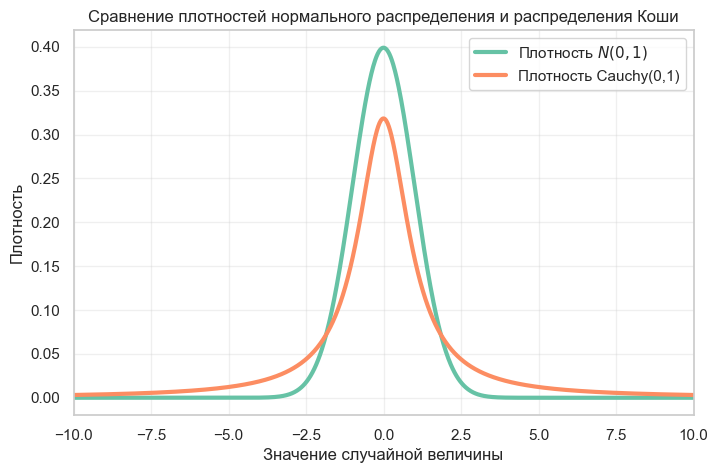

In [60]:
x = np.linspace(-10, 10, 1000)

normal_density = norm.pdf(x, loc=0, scale=1)
cauchy_density = cauchy.pdf(x, loc=0, scale=1)

plt.figure(figsize=(8, 5))
plt.plot(x, normal_density, lw=3, label="Плотность $N(0,1)$")
plt.plot(x, cauchy_density, lw=3, label="Плотность Cauchy(0,1)")
plt.title("Сравнение плотностей нормального распределения и распределения Коши")
plt.xlabel("Значение случайной величины")
plt.ylabel("Плотность")
plt.xlim(-10, 10)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Описание графика**

На графике изображены плотности стандартного нормального распределения $N(0,1)$ и распределения Коши $Cauchy(0,1)$.

В центре обе плотности имеют похожую форму, но у распределения Коши хвосты убывают заметно медленнее. Это значит, что большие по модулю значения у распределения Коши встречаются чаще, чем у нормального распределения.

**Вывод:**
Распределение Коши похоже на нормальное около нуля, но имеет более тяжёлые хвосты. Поэтому в выборках из распределения Коши чаще возникают очень большие выбросы.

**2.** Повторите эксперимент с <a href="https://thetahat.ru/courses/ad/main/9/2_lln" target="_top">занятия</a> про закон больших чисел для распределения Коши. Выполняется ли закон?

In [61]:
# Посмотрим, как меняется выборочное среднее при увеличении размера выборки
N_MAX = 5000
M = 10 # число независимых экспериментов
sample_sizes = np.arange(1, N_MAX + 1)

cauchy_sample = cauchy.rvs(size=N_MAX, random_state=42)
cumulative_means = np.cumsum(cauchy_sample) / sample_sizes

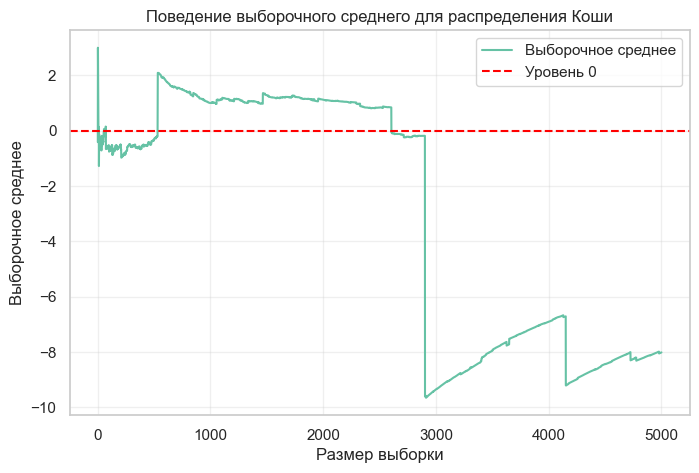

In [62]:
plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, cumulative_means, label="Выборочное среднее")
plt.axhline(0, color="red", linestyle="--", label="Уровень 0")
plt.title("Поведение выборочного среднего для распределения Коши")
plt.xlabel("Размер выборки")
plt.ylabel("Выборочное среднее")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

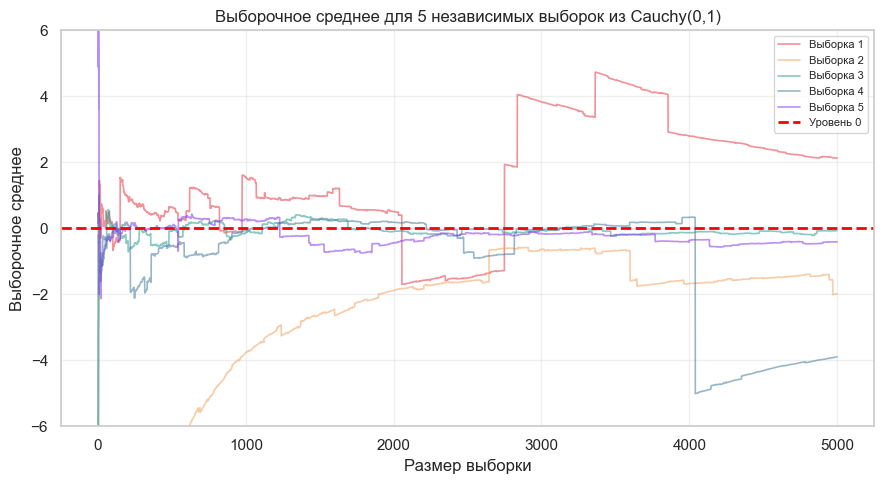

In [85]:
M = 5
colors = ["#E63946", "#F4A261", "#2A9D8F", "#457B9D", "#8338EC"]

fig, ax = plt.subplots(figsize=(9, 5))
for i in range(M):
    s = cauchy.rvs(size=N_MAX, random_state=i)
    ax.plot(sample_sizes, np.cumsum(s) / sample_sizes,
            alpha=0.55, lw=1.2, color=colors[i],
            label=f"Выборка {i+1}")
ax.axhline(0, color="red", linestyle="--", lw=2, label="Уровень 0")
ax.set_ylim(-6, 6)
ax.set_title(f"Выборочное среднее для {M} независимых выборок из Cauchy(0,1)")
ax.set_xlabel("Размер выборки")
ax.set_ylabel("Выборочное среднее")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Описание графика**

На графике показано, как меняется выборочное среднее для выборки из распределения Коши при увеличении размера выборки.
По оси x - размер выборки, а по оси y — соответствующее выборочное среднее.

**Вывод:**
Для распределения Коши закон больших чисел в обычном виде не выполняется. Выборочное среднее не стремится к некоторому устойчивому значению, а продолжает сильно колебаться из-за тяжёлых хвостов и редких, но очень больших выбросов.

**3.** Аналогичным образом проведите эксперимент по изучению сходимости *выборочной* медианы при увеличении размера выборки. Медиану по выборке можно посчитать с помощью <a target="_blank" href="https://numpy.org/doc/stable/reference/generated/numpy.median.html">`np.median`</a>.

In [64]:
# Вместо среднего посмотрим на медиану
#sample_sizes = np.arange(1, 5001)
#cauchy_sample = cauchy.rvs(size=5000)

cauchy_sample = cauchy.rvs(size=N_MAX, random_state=42)
cumulative_medians = [np.median(cauchy_sample[:n]) for n in sample_sizes]

cumulative_medians = []
for n in sample_sizes:
    cumulative_medians.append(np.median(cauchy_sample[:n]))

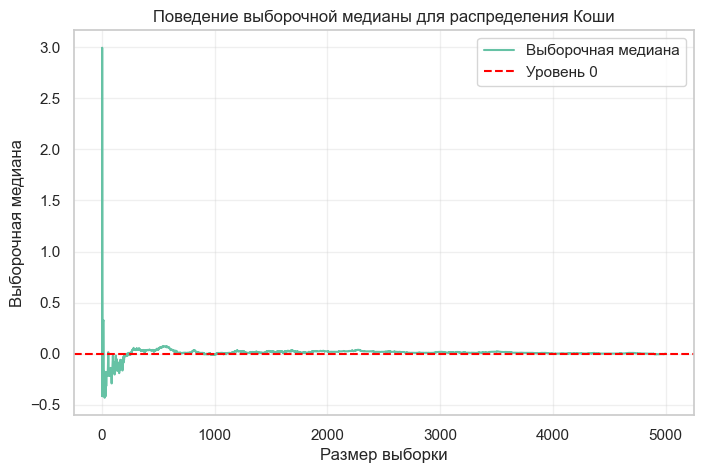

In [65]:
plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, cumulative_medians, label="Выборочная медиана")
plt.axhline(0, color="red", linestyle="--", label="Уровень 0")
plt.title("Поведение выборочной медианы для распределения Коши")
plt.xlabel("Размер выборки")
plt.ylabel("Выборочная медиана")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

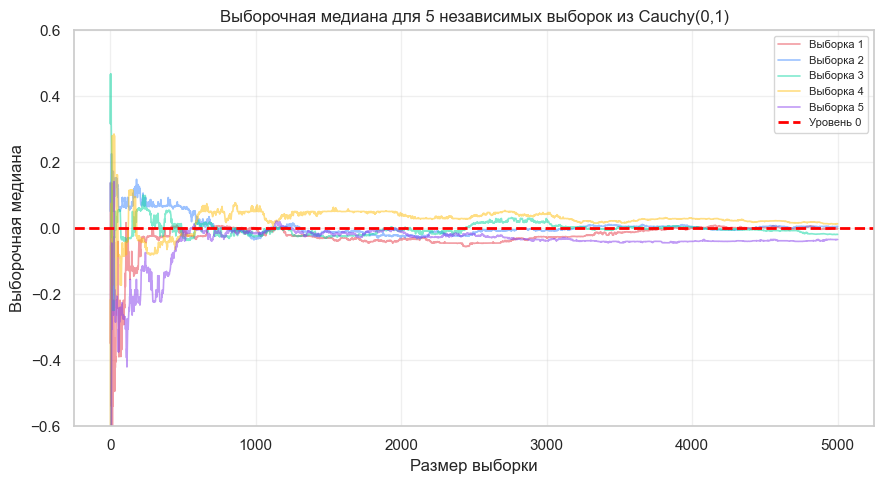

In [90]:
M = 5
colors = ["#E63946", "#3A86FF", "#06D6A0", "#FFBE0B", "#8338EC"]

fig, ax = plt.subplots(figsize=(9, 5))
for i in range(M):
    s = cauchy.rvs(size=N_MAX, random_state=i + 100)
    medians = [np.median(s[:n]) for n in sample_sizes]
    ax.plot(sample_sizes, medians,
            alpha=0.5, lw=1.2, color=colors[i],
            label=f"Выборка {i+1}")
ax.axhline(0, color="red", linestyle="--", lw=2, label="Уровень 0")
ax.set_ylim(-0.6, 0.6)
ax.set_title(f"Выборочная медиана для {M} независимых выборок из Cauchy(0,1)")
ax.set_xlabel("Размер выборки")
ax.set_ylabel("Выборочная медиана")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Описание графика**

На графике показано, как изменяется выборочная медиана для выборки из распределения Коши при увеличении размера выборки.
В отличие от выборочного среднего, медиана ведёт себя заметно устойчивее и колеблется значительно меньше.

**Вывод:**
Выборочная медиана для распределения Коши оказывается устойчивой и постепенно стабилизируется около нуля. Это связано с тем, что медиана гораздо менее чувствительна к выбросам, чем среднее.

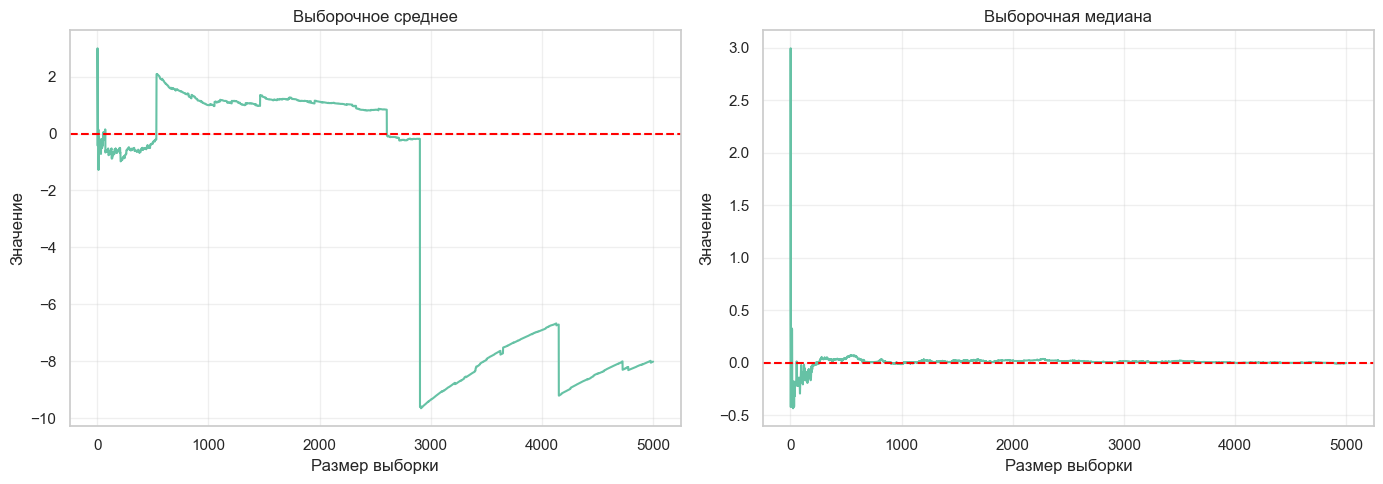

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(sample_sizes, cumulative_means)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Выборочное среднее")
axes[0].set_xlabel("Размер выборки")
axes[0].set_ylabel("Значение")
axes[0].grid(alpha=0.3)

axes[1].plot(sample_sizes, cumulative_medians)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Выборочная медиана")
axes[1].set_xlabel("Размер выборки")
axes[1].set_ylabel("Значение")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

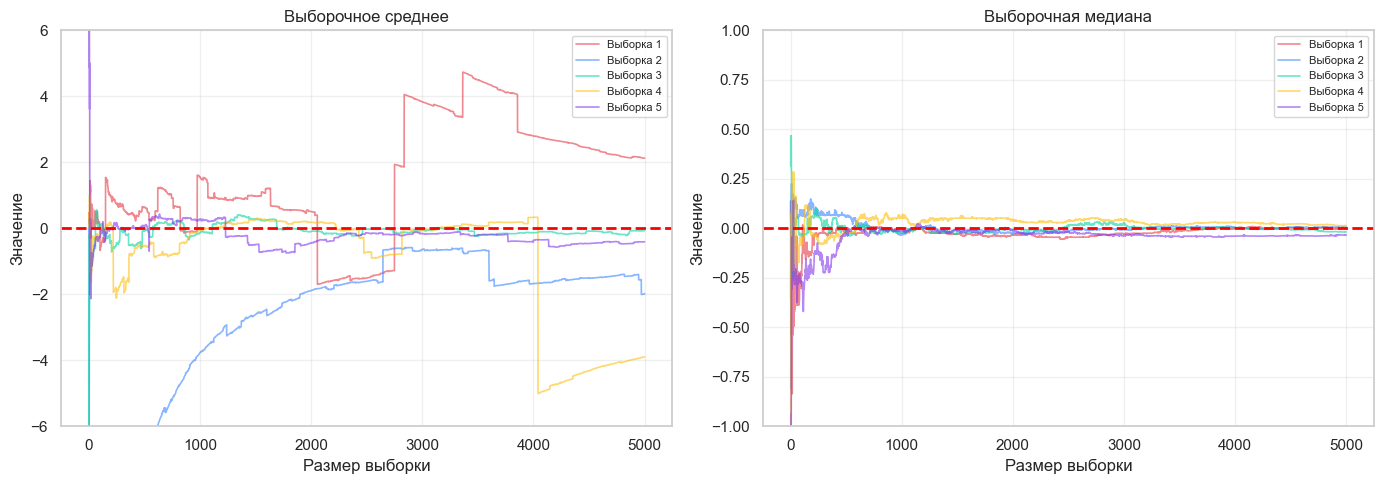

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ["#E63946", "#3A86FF", "#06D6A0", "#FFBE0B", "#8338EC"]

# Среднее
for i in range(M):
    s = cauchy.rvs(size=N_MAX, random_state=i)
    axes[0].plot(sample_sizes, np.cumsum(s) / sample_sizes,
                 alpha=0.6, lw=1.2, color=colors[i], label=f"Выборка {i+1}")
axes[0].axhline(0, color="red", linestyle="--", lw=2)
axes[0].set_ylim(-6, 6) 
axes[0].set_title("Выборочное среднее")
axes[0].set_xlabel("Размер выборки")
axes[0].set_ylabel("Значение")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Медиана
for i in range(M):
    s = cauchy.rvs(size=N_MAX, random_state=i + 100)
    medians = [np.median(s[:n]) for n in sample_sizes]
    axes[1].plot(sample_sizes, medians,
                 alpha=0.6, lw=1.2, color=colors[i], label=f"Выборка {i+1}")
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_ylim(-1, 1)
axes[1].set_title("Выборочная медиана")
axes[1].set_xlabel("Размер выборки")
axes[1].set_ylabel("Значение")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**4. Вывод:**



В ходе задания было исследовано распределение Коши и его отличие от нормального распределения.

Сравнение плотностей показало, что распределение Коши имеет тяжёлые хвосты: большие по модулю значения возникают значительно чаще, чем у нормального распределения.

Эксперимент с выборочным средним показал, что для распределения Коши закон больших чисел в привычном виде не выполняется: среднее не стабилизируется и может сильно меняться даже при больших размерах выборки.

В то же время выборочная медиана ведёт себя гораздо устойчивее и при увеличении размера выборки стабилизируется около нуля. Таким образом, для распределения Коши медиана оказывается более надёжной характеристикой центра, чем среднее.

---
### Задача 3.

Перед выполнением этой задачи настоятельно рекомендуется посмотреть <a href="https://thetahat.ru/courses/ad/main/9/2_lln" target="_top">ноутбук</a> с лекции про закон больших чисел.

На практике не редко возникает вопрос &mdash; **сколько времени потребуется на сбор данных, чтобы оценить среднее с достаточной точностью**. Для ответа на этот вопрос можно использовать различные теоретические оценки, в частности, неравенство Чебышева.

Другой способ &mdash; смоделировать большое количество выборок. Предположим, что мы сгенерировали $K$ выборок размера $n$ каждая, и $M_{nj}$ &mdash; *выборочное* среднее элементов в $j$-й выборке. Пусть математическое ожидание равно $a$, будем считать его известным в данной задаче. Тогда в качестве меры отклонения от среднего *среднее значение модуля отклонения от $a$*, то есть
$$F(n) = \frac{1}{K}\sum\limits_{j=1}^{K} \left|M_{nj} - a \right|,$$

**1.** Рассмотрим распределения $Bern(a)$ для $a=0.5$. Пусть для нас допустимо отклонение на 0.02, иначе говоря при *истинном* среднем 0.5 мы считаем достаточно точными значения *выборочного* среднего от 0.48 до 0.52. Тогда в качестве *приближения* необходимого размера выборок можно взять наименьшее значение $n$, при котором $F(n) \leqslant 0.02$.

Реализуйте данный эксперимент для $K=500$ и найдите значение $n$. Визуализируйте зависимость $F(n)$ от $n$ в обычном и логарифмическом масштабах (по тем осям, по которым это имеет смысл).

Для реализации без циклов стоит генерировать достаточно большие выборки и использовать функцию `np.where`.

In [123]:
K = 500
a = 0.5
eps = 0.02
max_n = 5000
np.random.seed(42)

# Генерируем K выборок длины max_n из Bern(a)
samples = np.random.binomial(1, a, size=(K, max_n))

cumulative_sums = np.cumsum(samples, axis=1)
sample_sizes = np.arange(1, max_n + 1)
sample_means = cumulative_sums / sample_sizes  # выборочное среднее для всех K и n

# Cреднее по всем выборкам отклонение sample_means от a
avg_errors = np.mean(np.abs(sample_means - a), axis=0)

# Минимальное n, при котором F(n) <= eps
n_min1 = np.where(avg_errors <= eps)[0][0] + 1

print(f"Минимальный размер выборки n: {n_min1}")

Минимальный размер выборки n: 362


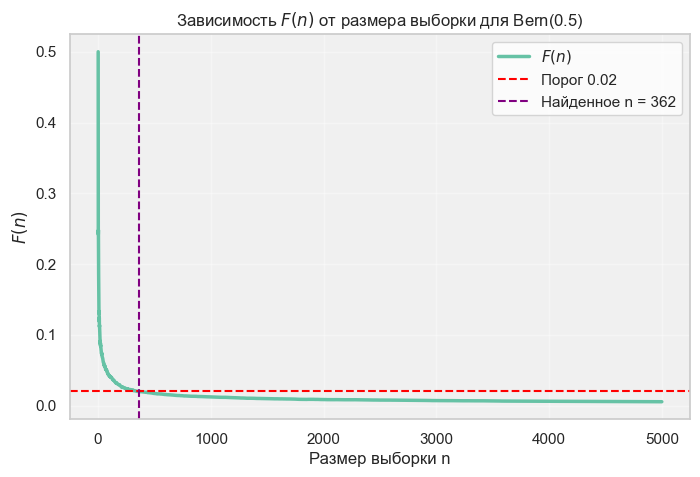

In [124]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_facecolor("#f0f0f0")
ax.plot(sample_sizes, avg_errors, lw=2.5, label="$F(n)$")
ax.axhline(eps, color="red", linestyle="--", label="Порог 0.02")
ax.axvline(n_min1, color="purple", linestyle="--", label=f"Найденное n = {n_min1}")
ax.set_title("Зависимость $F(n)$ от размера выборки для Bern(0.5)")
ax.set_xlabel("Размер выборки n")
ax.set_ylabel("$F(n)$")
ax.legend()
ax.grid(alpha=0.4, color="white")
plt.show()

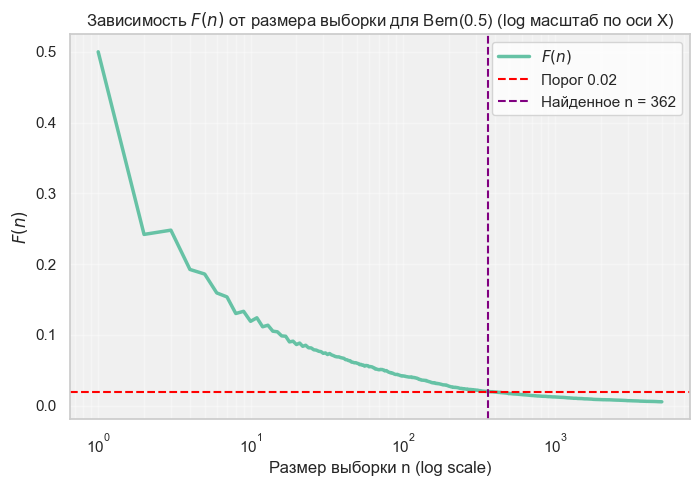

In [125]:
# График в логарифмическом масштабе
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_facecolor("#f0f0f0")
ax.plot(sample_sizes, avg_errors, lw=2.5, label="$F(n)$")
ax.axhline(eps, color="red", linestyle="--", label="Порог 0.02")
ax.axvline(n_min1, color="purple", linestyle="--", label=f"Найденное n = {n_min1}")
ax.set_xscale("log")
ax.set_title("Зависимость $F(n)$ от размера выборки для Bern(0.5) (log масштаб по оси X)")
ax.set_xlabel("Размер выборки n (log scale)")
ax.set_ylabel("$F(n)$")
ax.legend()
ax.grid(alpha=0.4, color="white", which="both")
plt.show()

**Описание графика**

На графике изображена зависимость средней ошибки выборочного среднего от размера выборки для распределения $Bern(0.5)$.
По оси x отложен размер выборки $n$, а по оси y — величина $F(n)$, то есть среднее по 500 выборкам значение отклонения выборочного среднего от истинного математического ожидания $a=0.5$.
Пунктирной горизонтальной линией отмечен допустимый уровень ошибки 0.02, а вертикальной линией — минимальное найденное значение $n$, при котором эта точность достигается.

**Вывод:**
При увеличении размера выборки величина $F(n)$ убывает, то есть выборочное среднее в среднем становится ближе к истинному значению. Это соответствует закону больших чисел. Минимальный размер выборки, обеспечивающий среднее отклонение не более 0.02, равен найденному значению $n$.

**2.** Повторите эксперимент из пункта 1 для значений $a$ от 0.05 до 0.95 с шагом 0.05. Визуализируйте зависимость необходимого размера выборки $n$ от значения $a$.

При реализации можно сделать цикл по значениям $a$.

In [126]:
K = 500
eps = 0.02
max_n = 5000

a_values = np.arange(0.05, 1.00, 0.05)
n_min_values = []

for a in a_values:
    samples = np.random.binomial(1, a, size=(K, max_n))
    cumulative_sums = np.cumsum(samples, axis=1)
    sample_sizes = np.arange(1, max_n + 1)
    sample_means = cumulative_sums / sample_sizes
    avg_errors = np.mean(np.abs(sample_means - a), axis=0)

    n_min = np.where(avg_errors <= eps)[0][0] + 1
    n_min_values.append(n_min)

n_min_values = np.array(n_min_values)
print(f"Минимальный размер выборки n: {n_min}")

Минимальный размер выборки n: 74


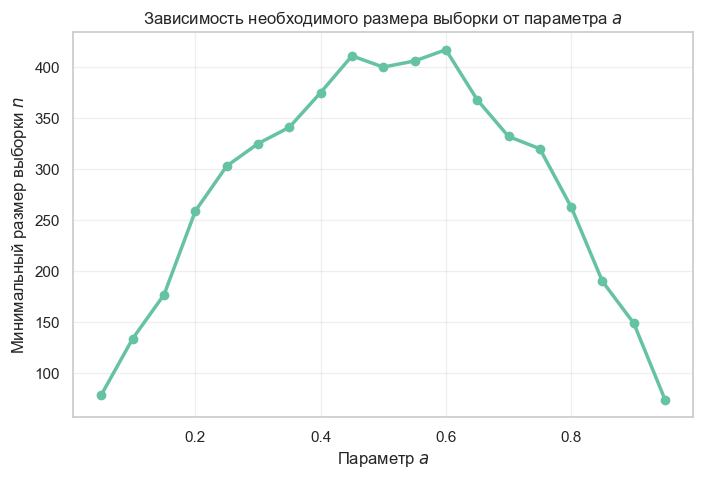

In [128]:
plt.figure(figsize=(8, 5))

plt.plot(a_values, n_min_values, marker="o", lw=2.5)
plt.title("Зависимость необходимого размера выборки от параметра $a$")
plt.xlabel("Параметр $a$")
plt.ylabel("Минимальный размер выборки $n$")
plt.grid(alpha=0.3)
plt.show()

**Описание графика**

На графике показано, как зависит минимальный необходимый размер выборки $n$ от параметра $a$ в распределении $Bern(a)$.
Для каждого значения $a$ находилось минимальное $n$, при котором среднее отклонение выборочного среднего от истинного значения не превышает 0.02.

**Вывод:**
Минимальный размер выборки зависит от значения параметра $a$. Наибольший размер выборки требуется вблизи $a=0.5$, так как в этой точке дисперсия распределения Бернулли максимальна. При значениях $a$, близких к 0 или 1, выборочное среднее стабилизируется быстрее, и нужный размер выборки оказывается меньше.

**3.** В теории часто предполагается независимость элементов выборки, однако, на практике это не всегда так. Исследуем, насколько это влияет на сходимость средних. Повторите эксперимент пункта 1, используя вместо выборки генерацию марковской цепи на значениях 0 и 1 с матрицей переходных вероятностей
$$
\begin{pmatrix}
p & 1-p \\
1-p & p
\end{pmatrix}.
$$

При $p=1/2$ мы получаем генерацию выборки из независимых случайных величин $Bern(1/2)$. При других значениях $p$ мы также получаем случайные величины из $Bern(1/2)$, но они уже зависимы друг с другом.

Проведите эксперимент для значений $p$ от 0.05 до 0.95 с шагом 0.05. Визуализируйте зависимость необходимого размера выборки $n$ от значения $p$.

In [133]:
K = 500
eps = 0.02
max_n = 5000
true_mean = 0.5

p_values = np.arange(0.05, 1.00, 0.05)
n_min_values = []

def generate_markov_chains(p, K, max_n):
    """Генерирует цепь Маркова на {0,1} с матрицей [[p, 1-p], [1-p, p]]"""
    chains = np.zeros((K, max_n), dtype=int)
    # Начальные состояния для всех K цепей сразу
    chains[:, 0] = np.random.binomial(1, 0.5, size=K)

    for i in range(1, max_n):
        # Для каждой цепи бросаем монету: остаёмся (< p) или переходим (>= p)
        rand = np.random.rand(K)
        stay = rand < p
        # Если остаёмся — берём то же состояние, иначе — 1, т.е предыдущее
        chains[:, i] = np.where(stay, chains[:, i-1], 1 - chains[:, i-1])

    return chains

for p in p_values:
    np.random.seed(42)
    samples = generate_markov_chains(p, K, max_n)

    cumulative_sums = np.cumsum(samples, axis=1)
    sample_sizes = np.arange(1, max_n + 1)
    sample_means = cumulative_sums / sample_sizes
    avg_errors = np.mean(np.abs(sample_means - true_mean), axis=0)

    reached = np.where(avg_errors <= eps)[0]
    n_min = reached[0] + 1 if len(reached) > 0 else max_n
    n_min_values.append(n_min)

n_min_values = np.array(n_min_values)
print(f"Минимальное n: {n_min_values.min()} при p = {p_values[n_min_values.argmin()]:.2f}")
print(f"Максимальное n: {n_min_values.max()} при p = {p_values[n_min_values.argmax()]:.2f}")

n_at_05 = n_min_values[np.isclose(p_values, 0.5)][0]
print(f"Пункт 1 — n_min = {n_min1}")
print(f"Пункт 3 — при p=0.5: n_min = {n_at_05}")
print(f"Разница: {abs(n_at_05 - n_min1)}")

Минимальное n: 4 при p = 0.05
Максимальное n: 5000 при p = 0.95
Пункт 1 — n_min = 362
Пункт 3 — при p=0.5: n_min = 409
Разница: 47


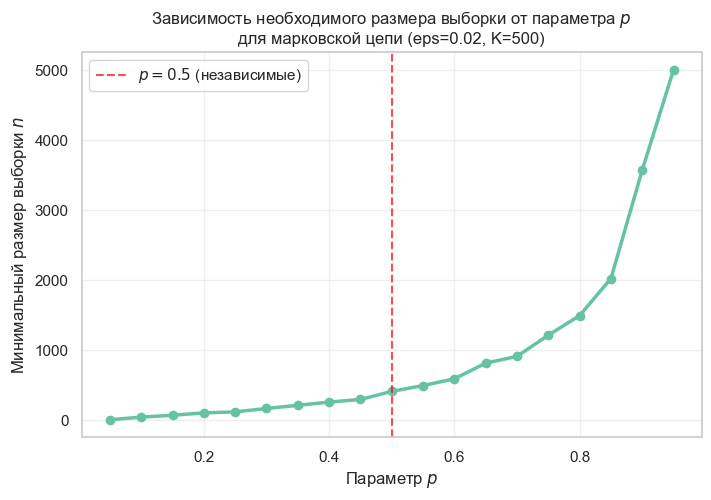

In [134]:
plt.figure(figsize=(8, 5))
plt.plot(p_values, n_min_values, marker="o", lw=2.5, markersize=6)
plt.axvline(0.5, color="red", linestyle="--", alpha=0.7, label="$p = 0.5$ (независимые)")
plt.title(f"Зависимость необходимого размера выборки от параметра $p$\nдля марковской цепи (eps={eps}, K={K})")
plt.xlabel("Параметр $p$")
plt.ylabel("Минимальный размер выборки $n$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Описание графика**

На графике показана зависимость минимального размера выборки $n$ от параметра $p$ матрицы переходных вероятностей марковской цепи. Для каждого значения $p$ подбирался минимальный $n$, при котором среднее отклонение выборочного среднего от истинного значения 0.5 не выше $eps = 0.02$. Вертикальной пунктирной линией показано значение $p = 0.5$, при котором наблюдения становятся независимыми. В этой точке требуемый размер выборки минимальный. При отклонении $p$ от 0.5 видно, что необходимый размер выборки начинает расти, причём особенно резко при $p \to 1$.

**Вывод:**
При $p = 0.5$ элементы цепи независимы, поэтому оценка среднего сходится быстрее всего, и требуется наименьший размер выборки.
Когда $p$ отклоняется от 0.5, появляется зависимость между соседними наблюдениями. Из-за этого новая информация в выборке добавляется медленнее, и для достижения той же точности нужно больше данных.
Особенно сильно это видно при $p \to 1$, когда цепь надолго остаётся в одном состоянии. В этом случае наблюдения становятся почти одинаковыми, новой информации почти нет, и для той же точности нужно сильно увеличивать объём выборки.

**4. Выводы:**

В этой задаче рассмотрели, как зависимость между наблюдениями влияет на точность оценки среднего.
В отличие от предыдущих пунктов, где все наблюдения были независимыми, в третьем использовалась марковская цепь, в которой соседние элементы могут зависеть друг от друга. Хотя математическое ожидание во всех случаях остаётся равным 0.5, скорость сходимости сильно меняется.

При $p = 0.5$ элементы цепи независимы, поэтому оценка среднего сходится быстрее всего, и требуется наименьший размер выборки.

Когда $p$ отклоняется от 0.5, появляется зависимость между соседними наблюдениями. Из-за этого значения начинают повторяться, и в выборке становится меньше новой информации. Поэтому для достижения той же точности нужно больше данных.

Особенно это заметно при $p \to 1$, когда цепь долго остаётся в одном состоянии. В результате в выборке появляются длинные последовательности одинаковых значений, и для точной оценки среднего требуется значительно больше наблюдений.

В итоге, чем сильнее зависимость, тем больше наблюдений нужно, чтобы получить такую же точность оценки.

**Главный вывод:** независимость наблюдений играет очень важную роль — если её нет, то для достижения той же точности требуется значительно больший размер выборки.

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для ВвАД